# 🧪 Ethereum Phishing Risk Detection — Notebook Eksperimen (Tesis)

Notebook ini **menjalankan ulang seluruh eksperimen dari nol** (bukan sekadar membaca artifact),
dan menghasilkan semua bahan yang dibutuhkan untuk BAB 4 tesis:

| # | Bagian |
|---|---|
| 1 | Setup, konfigurasi, & load MulDiGraph |
| 2 | Statistik dataset & skema fitur |
| 3 | **Eksperimen utama**: 4 skenario × 4 model (LR, RF, XGBoost, GNN-GraphSAGE) |
| 4 | Tabel hasil + visualisasi (bar, heatmap, dampak Etherscan) |
| 5 | **Confusion matrix SEMUA model** (skenario terbaik + seluruh skenario) |
| 6 | Feature importance (RF & XGBoost) |
| 7 | **Eksperimen sampling ratio 1:5 vs 1:10** (RQ3) |
| 8 | Threshold analysis (XGBoost) |
| 9 | Classification report tiap model |
| 10 | Metrik blockchain (latency & gas, RQ2) |
| 11 | Ringkasan & jawaban Research Questions |

> **Cara pakai:** `Kernel → Restart & Run All`. Estimasi total runtime ~5–7 menit
> (load graph ~45 dtk + 4× training GNN + sampling). Semua angka **reproducible** (seed 42).

## 1. ⚙️ Setup & Konfigurasi

In [1]:
import sys, json, time, pickle, random, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore")

# ── Deteksi root repo & path
here = Path.cwd()
ROOT = next((p for p in [here, *here.parents] if (p / "ml" / "artifacts").exists()), here)
ART  = ROOT / "ml" / "artifacts"
DATA = ROOT / "data" / "processed"
sys.path.insert(0, str(ROOT))
sys.path.insert(0, str(ROOT / "ml"))

# ── Konfigurasi eksperimen
SEED = 42
USE_REAL_EDGES   = True   # GNN pakai edge transaksi nyata dari MulDiGraph (butuh file .pkl)
RUN_GNN          = True   # set False utk skip GNN (lebih cepat)
RUN_SAMPLING     = True   # eksperimen 1:5 vs 1:10 (butuh MulDiGraph)

random.seed(SEED); np.random.seed(SEED)
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")
plt.rcParams["figure.dpi"] = 110
print("ROOT:", ROOT)
print("numpy", np.__version__, "| pandas", pd.__version__)

ROOT: C:\Kuliah\ethereum-phising-risk-detection
numpy 2.4.4 | pandas 3.0.2


In [2]:
# Import modul project (XGBoost & GNN identik dengan pipeline asli)
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, ConfusionMatrixDisplay, classification_report,
                             precision_recall_curve)
from xgboost_model import XGBoostModel

HAVE_TORCH = False
if RUN_GNN:
    try:
        import torch
        from gnn_model_v2 import GraphPhiV2
        from train_dataset_scenarios import extract_edges_for_addresses
        HAVE_TORCH = True
        print("PyTorch", torch.__version__, "— GNN aktif")
    except Exception as e:
        print("⚠️ GNN dimatikan (torch/PyG tak tersedia):", e)

# train_dataset_scenarios memaksa backend "Agg" saat di-import — kembalikan ke inline
try:
    from IPython import get_ipython
    get_ipython().run_line_magic("matplotlib", "inline")
except Exception:
    pass
print("XGBoostModel siap.")

PyTorch 2.11.0+cpu — GNN aktif
XGBoostModel siap.


In [3]:
# Load MulDiGraph sekali (dipakai utk edge GNN & eksperimen sampling)
GRAPH_PATH = ROOT / "data" / "raw" / "MulDiGraph.pkl"
G = None
if (USE_REAL_EDGES or RUN_SAMPLING) and GRAPH_PATH.exists():
    print("Loading MulDiGraph (~45 dtk, 1.25 GB) ...")
    t0 = time.time()
    with open(GRAPH_PATH, "rb") as f:
        G = pickle.load(f)
    print(f"  loaded in {time.time()-t0:.0f}s — {G.number_of_nodes():,} nodes, {G.number_of_edges():,} edges")
else:
    print("MulDiGraph tidak dimuat — GNN akan pakai kNN fallback, sampling pakai artifact.")

Loading MulDiGraph (~45 dtk, 1.25 GB) ...


  loaded in 36s — 2,973,489 nodes, 13,551,303 edges


## 2. 📂 Statistik Dataset & Skema Fitur

In [4]:
df = pd.read_csv(DATA / "hybrid_dataset.csv")
schema = json.load(open(ART / "hybrid_feature_schema.json"))

print(f"Total alamat : {len(df):,}")
print(f"Phishing     : {int(df.label.sum()):,}  ({df.label.mean()*100:.1f}%)")
print(f"Normal       : {int((df.label==0).sum()):,}")
print(f"Total kolom  : {df.shape[1]}")

groups = schema["feature_groups"]
print("\nKelompok fitur:")
for g, feats in groups.items():
    print(f"  {g:10s}: {len(feats)} fitur")
print("\nSkenario (jumlah fitur):")
for s, feats in schema["scenarios"].items():
    print(f"  {s:42s}: {len([f for f in feats if f in df.columns])}")
df.head(3)

Total alamat : 8,595
Phishing     : 1,165  (13.6%)
Normal       : 7,430
Total kolom  : 41

Kelompok fitur:
  graph     : 19 fitur
  etherscan : 7 fitur
  bigquery  : 10 fitur

Skenario (jumlah fitur):
  muldigraph_only                           : 19
  muldigraph_plus_etherscan                 : 26
  muldigraph_plus_bigquery                  : 29
  muldigraph_plus_etherscan_plus_bigquery   : 36


,address,label,class_name,source_dataset,created_at_ts,balance,transaction_count,activity_score,avg_tx_value,tx_frequency,...,bq_tx_count_in,bq_total_out_eth,bq_total_in_eth,bq_unique_to,bq_unique_from,bq_active_days_out,bq_active_days_in,bq_first_seen_ts,bq_last_seen_ts,node_id
0,0x4f66f7e2de0a1f9848ac61278f61a69c2bd276be,0,normal,EPTransNet,0,0.0000,4,4,9.9863,0.1333,...,0,0.0000,0.0000,0,0,0,0,0.0000,0.0000,0x4f66f7e2de0a1f9848ac61278f61a69c2bd276be
1,0x737bc3bdba233527cecda3fad5712c75223c98ac,0,normal,EPTransNet,0,0.0000,2,2,1.3967,0.0667,...,0,0.0000,0.0000,0,0,0,0,0.0000,0.0000,0x737bc3bdba233527cecda3fad5712c75223c98ac
2,0x06ea254508f7822d11a44f699ef899a6d52866fc,0,normal,EPTransNet,0,0.0000,6,6,1.0016,0.2000,...,0,0.0000,0.0000,0,0,0,0,0.0000,0.0000,0x06ea254508f7822d11a44f699ef899a6d52866fc


In [5]:
# Split tunggal yang dipakai semua skenario (80/20, stratified, seed 42)
train_df, test_df = train_test_split(df, test_size=0.2, random_state=SEED, stratify=df["label"])
y_test = test_df["label"].values
print(f"train={len(train_df)}  test={len(test_df)}  phishing@test={int(y_test.sum())}")

SCENARIOS = {
    "muldigraph_only": "MulDiGraph only",
    "muldigraph_plus_etherscan": "MulDiGraph + Etherscan",
    "muldigraph_plus_bigquery": "MulDiGraph + BigQuery",
    "muldigraph_plus_etherscan_plus_bigquery": "MulDiGraph + Etherscan + BigQuery",
}
scenario_feats = {s: [f for f in schema["scenarios"][s] if f in df.columns] for s in SCENARIOS}

train=6876  test=1719  phishing@test=233


## 3. 🔬 Eksperimen Utama — 4 Skenario × 4 Model

Tiap skenario melatih: **Logistic Regression, Random Forest, XGBoost, GNN-GraphSAGE V2**.
Prediksi tiap model disimpan untuk confusion matrix di bagian 5.

In [6]:
def metric_row(scenario, model, y_true, y_pred):
    return dict(scenario=scenario, model=model,
                accuracy=accuracy_score(y_true, y_pred),
                precision=precision_score(y_true, y_pred, zero_division=0),
                recall=recall_score(y_true, y_pred, zero_division=0),
                f1=f1_score(y_true, y_pred, zero_division=0))

def fit_lr(Xtr, ytr, Xte):
    sc = StandardScaler()
    lr = LogisticRegression(max_iter=1000, random_state=SEED, class_weight="balanced")
    lr.fit(sc.fit_transform(Xtr), ytr)
    return lr.predict(sc.transform(Xte)), None

def fit_rf(Xtr, ytr, Xte):
    rf = RandomForestClassifier(n_estimators=200, min_samples_leaf=2,
                                class_weight="balanced", n_jobs=-1, random_state=SEED)
    rf.fit(Xtr, ytr)
    return rf.predict(Xte), rf

def fit_xgb(Xtr, ytr, Xte, feat_names):
    Xf, Xv, yf, yv = train_test_split(Xtr, ytr, test_size=0.2, random_state=SEED, stratify=ytr)
    m = XGBoostModel(n_estimators=250, max_depth=6, learning_rate=0.05,
                     subsample=0.85, colsample_bytree=0.85)
    m.fit(Xf, yf, Xv, yv, feature_names=feat_names, early_stopping_rounds=40)
    return m.predict(Xte), m

def fit_gnn(scenario, Xtr, ytr, Xte, yte, feat_names):
    sc = StandardScaler(); Xtr_s = sc.fit_transform(Xtr); Xte_s = sc.transform(Xte)
    edges = None
    if USE_REAL_EDGES and G is not None:
        tr_addr = train_df["node_id"].astype(str).str.lower().tolist()
        te_addr = test_df["node_id"].astype(str).str.lower().tolist()
        edges = extract_edges_for_addresses(G, tr_addr, te_addr)
    torch.manual_seed(SEED); np.random.seed(SEED)
    gnn = GraphPhiV2(model_type="sage", input_dim=len(feat_names), hidden_dim=128, num_layers=2)
    if edges:
        g, trm, tem = gnn.build_graph_with_real_edges(Xtr_s, ytr, Xte_s, yte, edges)
    else:
        g, trm, tem = gnn.build_graph_from_train_only(Xtr_s, ytr, Xte_s, yte)
    gnn.fit(g, train_mask=trm, test_mask=tem, epochs=200, early_stopping_patience=25)
    pred, _ = gnn.predict(g, tem)
    return pred, None

In [7]:
results, preds, models_fitted = [], {}, {}
t0 = time.time()
for s, feats in scenario_feats.items():
    Xtr = train_df[feats].fillna(0).values; ytr = train_df["label"].values
    Xte = test_df[feats].fillna(0).values
    print(f"▶ {SCENARIOS[s]} ({len(feats)} fitur)")

    p, _   = fit_lr(Xtr, ytr, Xte);              results.append(metric_row(s,"LogisticRegression",y_test,p)); preds[(s,"LogisticRegression")]=p
    p, rf  = fit_rf(Xtr, ytr, Xte);              results.append(metric_row(s,"RandomForest",y_test,p));        preds[(s,"RandomForest")]=p;  models_fitted[(s,"RandomForest")]=rf
    p, xm  = fit_xgb(Xtr, ytr, Xte, feats);      results.append(metric_row(s,"XGBoost",y_test,p));             preds[(s,"XGBoost")]=p;       models_fitted[(s,"XGBoost")]=xm
    if HAVE_TORCH:
        p,_= fit_gnn(s, Xtr, ytr, Xte, y_test, feats); results.append(metric_row(s,"GNN-GraphSAGE-V2",y_test,p)); preds[(s,"GNN-GraphSAGE-V2")]=p
    print(f"   ✓ selesai ({time.time()-t0:.0f}s berlalu)")

res = pd.DataFrame(results)
print(f"\nTotal waktu eksperimen: {time.time()-t0:.0f}s")

▶ MulDiGraph only (19 fitur)


12:28:15  INFO      Initialized XGBoost: estimators=250, depth=6, lr=0.050


12:28:15  INFO      Training XGBoost with scale_pos_weight=6.38


[0]	train-logloss:0.64957	val-logloss:0.65072


[50]	train-logloss:0.09165	val-logloss:0.11863


...

12:29:05  INFO      [Epoch  60] loss=0.3271  test_f1=0.7807  best=0.8077  patience=2/25


12:29:08  INFO      [Epoch  80] loss=0.2634  test_f1=0.7859  best=0.8077  patience=22/25


12:29:08  INFO      Early stopping at epoch 83 (best F1=0.8077)


12:29:08  INFO      Restored best weights (F1=0.8077)


   ✓ selesai (54s berlalu)

Total waktu eksperimen: 54s


## 4. 📊 Tabel Hasil & Visualisasi

In [8]:
view = res.copy()
for c in ["accuracy","precision","recall","f1"]:
    view[c] = (view[c]*100).round(2)
view["scenario"] = view["scenario"].map(SCENARIOS)
view = view.rename(columns={"scenario":"Skenario","model":"Model","accuracy":"Acc %",
                            "precision":"Prec %","recall":"Recall %","f1":"F1 %"})
best = res.loc[res.f1.idxmax()]
print(f"🏆 Terbaik: {best['model']} @ {SCENARIOS[best['scenario']]} — F1 {best['f1']*100:.2f}%\n")
try:
    display(view.style.background_gradient(subset=["F1 %"], cmap="Greens")
            .set_caption("Hasil eksperimen 4 skenario × 4 model"))
except Exception:
    print(view.to_string(index=False))

🏆 Terbaik: XGBoost @ MulDiGraph + Etherscan — F1 91.02%



,Skenario,Model,Acc %,Prec %,Recall %,F1 %
0,MulDiGraph only,LogisticRegression,94.650000,86.150000,72.100000,78.500000
1,MulDiGraph only,RandomForest,96.280000,84.210000,89.270000,86.670000
2,MulDiGraph only,XGBoost,96.800000,85.890000,91.420000,88.570000
3,MulDiGraph only,GNN-GraphSAGE-V2,95.110000,77.090000,90.990000,83.460000
4,MulDiGraph + Etherscan,LogisticRegression,96.160000,88.130000,82.830000,85.400000
5,MulDiGraph + Etherscan,RandomForest,96.920000,86.590000,91.420000,88.940000
6,MulDiGraph + Etherscan,XGBoost,97.500000,88.620000,93.560000,91.020000
7,MulDiGraph + Etherscan,GNN-GraphSAGE-V2,96.970000,83.900000,96.140000,89.600000
8,MulDiGraph + BigQuery,LogisticRegression,94.710000,86.220000,72.530000,78.790000
9,MulDiGraph + BigQuery,RandomForest,96.390000,84.620000,89.700000,87.080000


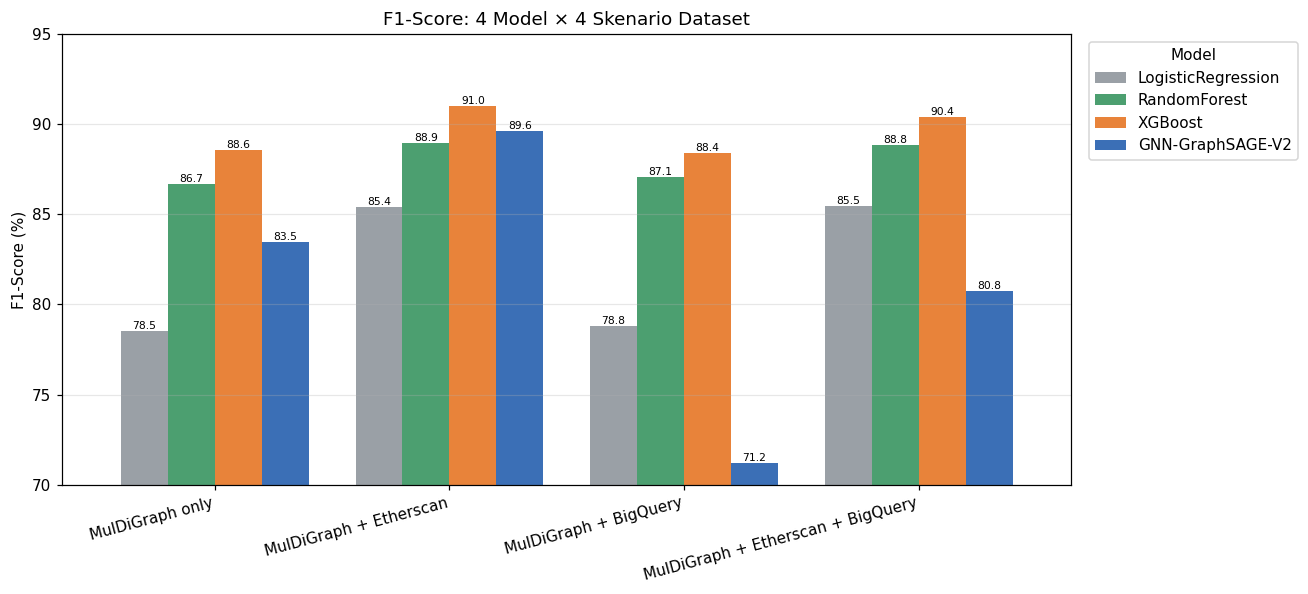

In [9]:
MODEL_ORDER = ["LogisticRegression","RandomForest","XGBoost","GNN-GraphSAGE-V2"]
MODEL_ORDER = [m for m in MODEL_ORDER if m in res.model.unique()]
COLORS = {"LogisticRegression":"#9aa0a6","RandomForest":"#4c9f70",
          "XGBoost":"#e8833a","GNN-GraphSAGE-V2":"#3b6fb6"}
pivot = res.pivot(index="scenario", columns="model", values="f1").reindex(list(SCENARIOS))[MODEL_ORDER]*100

ax = pivot.plot(kind="bar", figsize=(12,5.5), width=0.8, color=[COLORS[m] for m in MODEL_ORDER])
ax.set_ylabel("F1-Score (%)"); ax.set_xlabel("")
ax.set_title("F1-Score: 4 Model × 4 Skenario Dataset")
ax.set_xticklabels([SCENARIOS[s] for s in pivot.index], rotation=15, ha="right")
ax.set_ylim(70, 95); ax.legend(title="Model", bbox_to_anchor=(1.01,1), loc="upper left")
for c in ax.containers: ax.bar_label(c, fmt="%.1f", fontsize=7)
ax.grid(axis="y", alpha=0.3); plt.tight_layout(); plt.show()

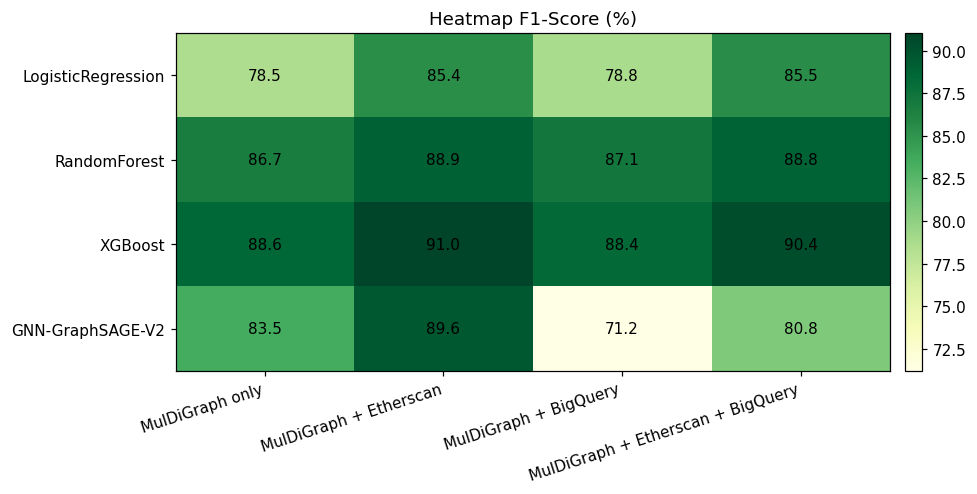

In [10]:
# Heatmap
fig, ax = plt.subplots(figsize=(9,4.6))
data = pivot.T
im = ax.imshow(data.values, cmap="YlGn", aspect="auto")
ax.set_xticks(range(len(SCENARIOS))); ax.set_xticklabels([SCENARIOS[s] for s in pivot.index], rotation=18, ha="right")
ax.set_yticks(range(len(data.index))); ax.set_yticklabels(data.index)
for i in range(data.shape[0]):
    for j in range(data.shape[1]):
        ax.text(j, i, f"{data.values[i,j]:.1f}", ha="center", va="center")
ax.set_title("Heatmap F1-Score (%)"); fig.colorbar(im, ax=ax, fraction=0.025, pad=0.02)
plt.tight_layout(); plt.show()

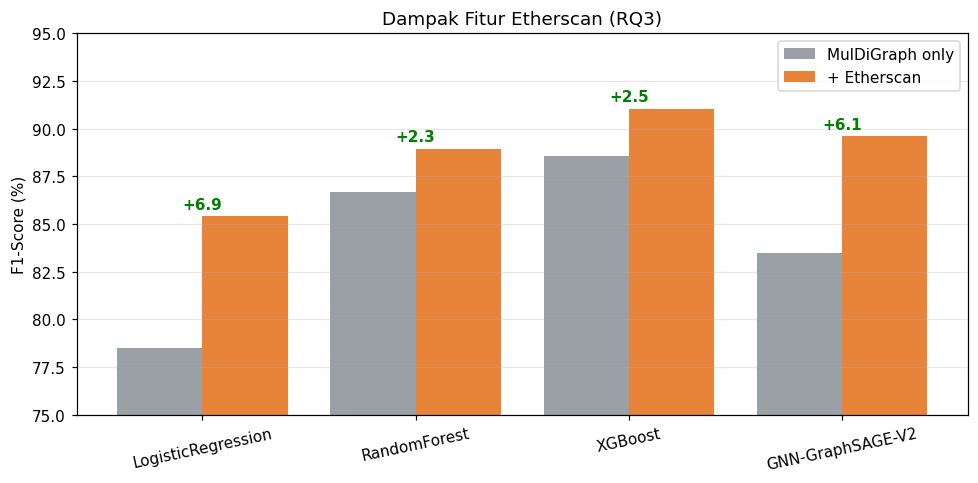

In [11]:
# Dampak Etherscan (skenario 1 -> 2)
s1 = res[res.scenario=="muldigraph_only"].set_index("model")["f1"]*100
s2 = res[res.scenario=="muldigraph_plus_etherscan"].set_index("model")["f1"]*100
fig, ax = plt.subplots(figsize=(9,4.5)); x=np.arange(len(MODEL_ORDER))
ax.bar(x-0.2, s1.reindex(MODEL_ORDER), 0.4, label="MulDiGraph only", color="#9aa0a6")
ax.bar(x+0.2, s2.reindex(MODEL_ORDER), 0.4, label="+ Etherscan", color="#e8833a")
for i,m in enumerate(MODEL_ORDER):
    ax.annotate(f"+{s2[m]-s1[m]:.1f}", (i, max(s1[m],s2[m])+0.4), ha="center", color="green", fontweight="bold")
ax.set_xticks(x); ax.set_xticklabels(MODEL_ORDER, rotation=12); ax.set_ylim(75,95)
ax.set_ylabel("F1-Score (%)"); ax.set_title("Dampak Fitur Etherscan (RQ3)"); ax.legend(); ax.grid(axis="y",alpha=0.3)
plt.tight_layout(); plt.show()

## 5. 🧩 Confusion Matrix — SEMUA Model

### 5a. Skenario terbaik (MulDiGraph + Etherscan)

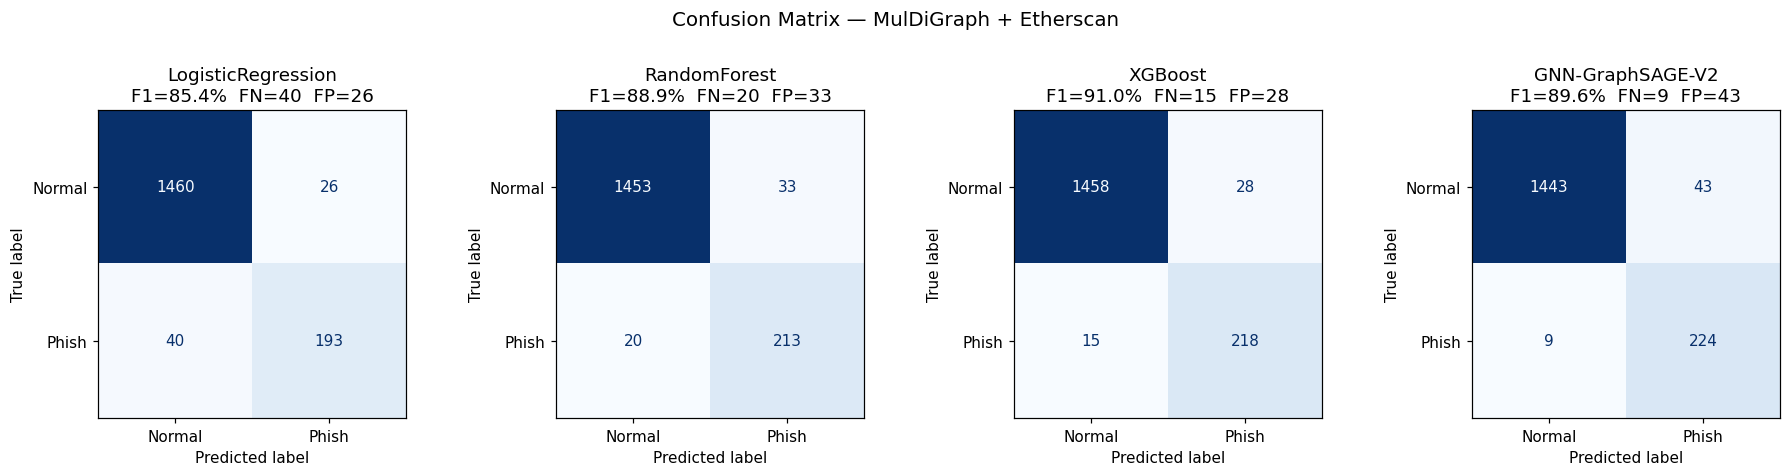

In [12]:
def show_cm_grid(scenario, models):
    n = len(models)
    fig, axes = plt.subplots(1, n, figsize=(4.2*n, 4))
    if n == 1: axes = [axes]
    for ax, m in zip(axes, models):
        if (scenario, m) not in preds:
            ax.axis("off"); ax.set_title(f"{m}\n(N/A)"); continue
        cm = confusion_matrix(y_test, preds[(scenario, m)])
        ConfusionMatrixDisplay(cm, display_labels=["Normal","Phish"]).plot(
            ax=ax, colorbar=False, cmap="Blues", values_format="d")
        tn, fp, fn, tp = cm.ravel()
        f1 = res[(res.scenario==scenario)&(res.model==m)]["f1"].iloc[0]*100
        ax.set_title(f"{m}\nF1={f1:.1f}%  FN={fn}  FP={fp}")
    fig.suptitle(f"Confusion Matrix — {SCENARIOS[scenario]}", y=1.04, fontsize=13)
    plt.tight_layout(); plt.show()

show_cm_grid("muldigraph_plus_etherscan", MODEL_ORDER)

> **FN (False Negative)** = phishing lolos tak terdeteksi → metrik paling kritis untuk keamanan.
> GNN biasanya punya FN terendah (recall tertinggi), XGBoost paling seimbang (F1 tertinggi).

### 5b. Confusion matrix SEMUA skenario × SEMUA model (grid lengkap)

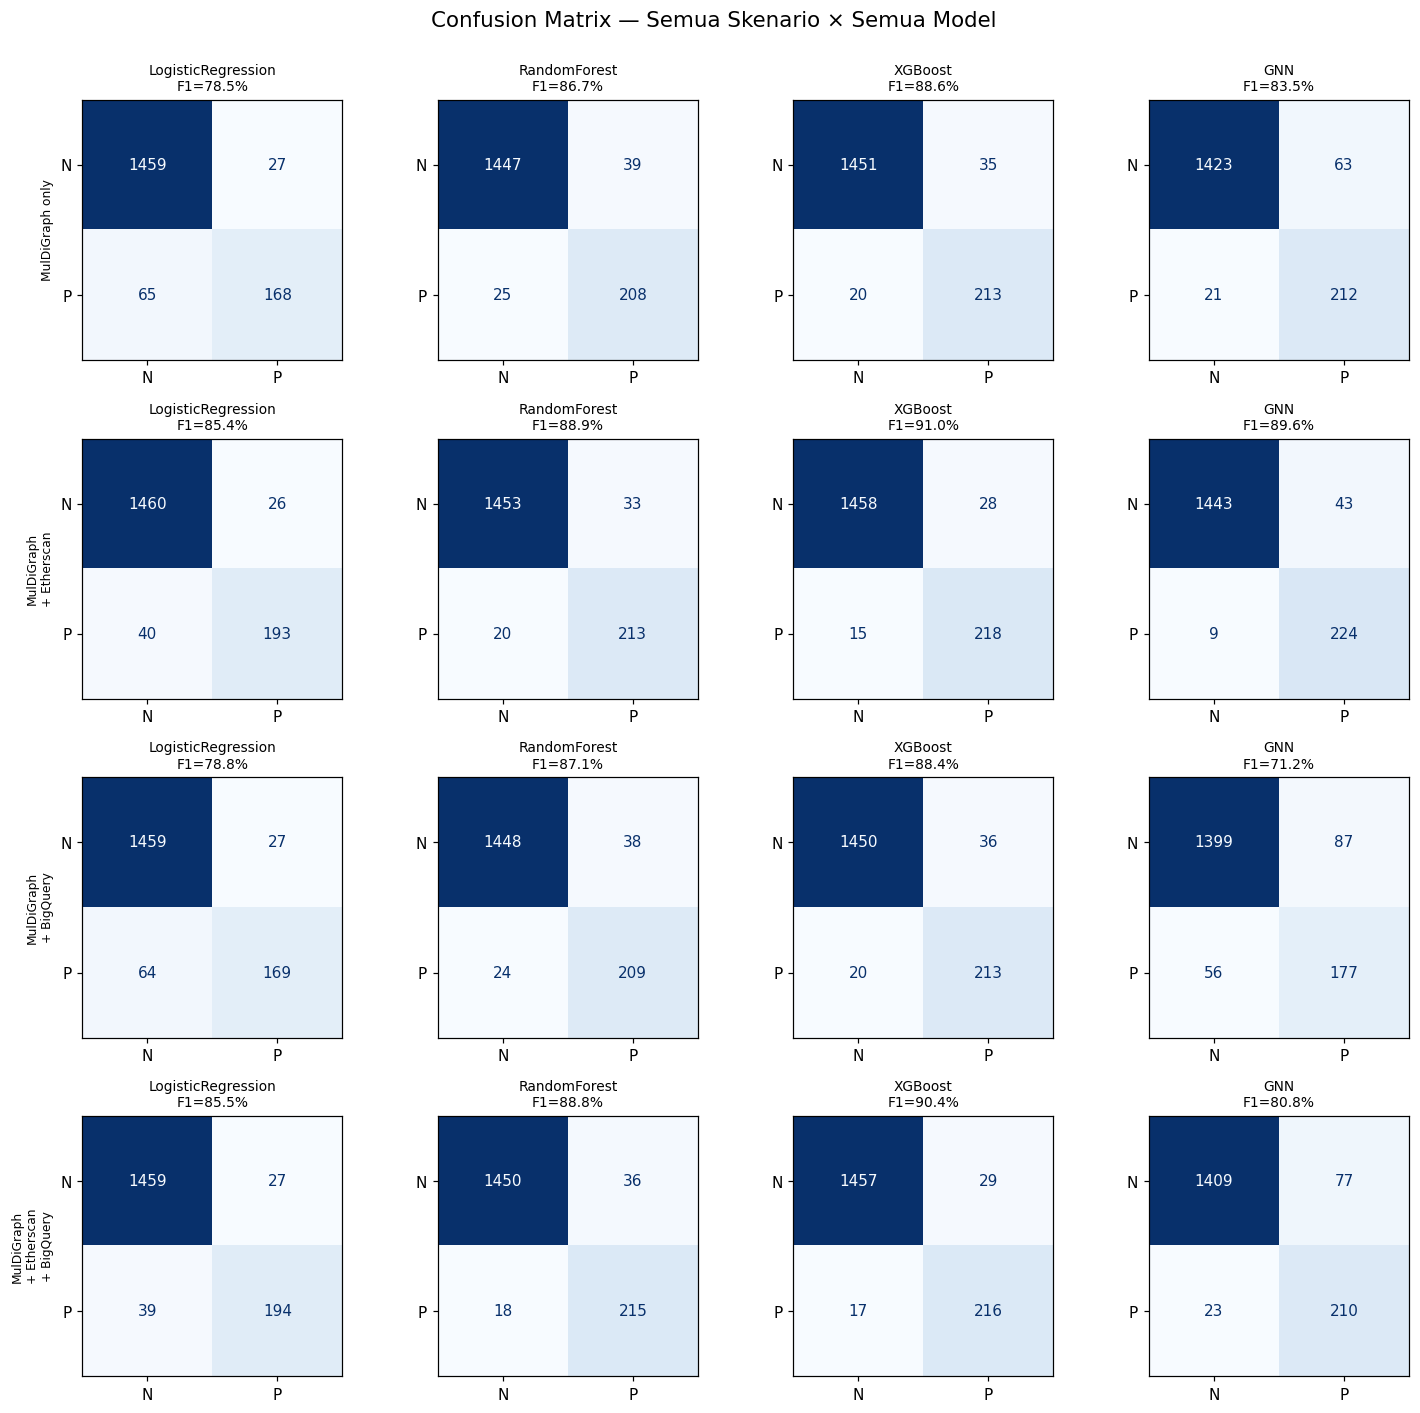

In [13]:
scs = list(SCENARIOS); n_row=len(scs); n_col=len(MODEL_ORDER)
fig, axes = plt.subplots(n_row, n_col, figsize=(3.4*n_col, 3.2*n_row))
for i, s in enumerate(scs):
    for j, m in enumerate(MODEL_ORDER):
        ax = axes[i][j]
        if (s, m) not in preds:
            ax.axis("off"); continue
        cm = confusion_matrix(y_test, preds[(s, m)])
        ConfusionMatrixDisplay(cm, display_labels=["N","P"]).plot(
            ax=ax, colorbar=False, cmap="Blues", values_format="d")
        f1 = res[(res.scenario==s)&(res.model==m)]["f1"].iloc[0]*100
        ax.set_title(f"{m.replace('-GraphSAGE-V2','')}\nF1={f1:.1f}%", fontsize=9)
        if j == 0: ax.set_ylabel(SCENARIOS[s].replace(' + ','\n+ '), fontsize=8)
        else: ax.set_ylabel("")
        ax.set_xlabel("")
fig.suptitle("Confusion Matrix — Semua Skenario × Semua Model", y=1.0, fontsize=14)
plt.tight_layout(); plt.show()

## 6. 🌟 Feature Importance (RQ3) — Random Forest & XGBoost

Skenario terbaik (MulDiGraph + Etherscan). Menjelaskan fitur mana yang paling
berpengaruh terhadap deteksi phishing.

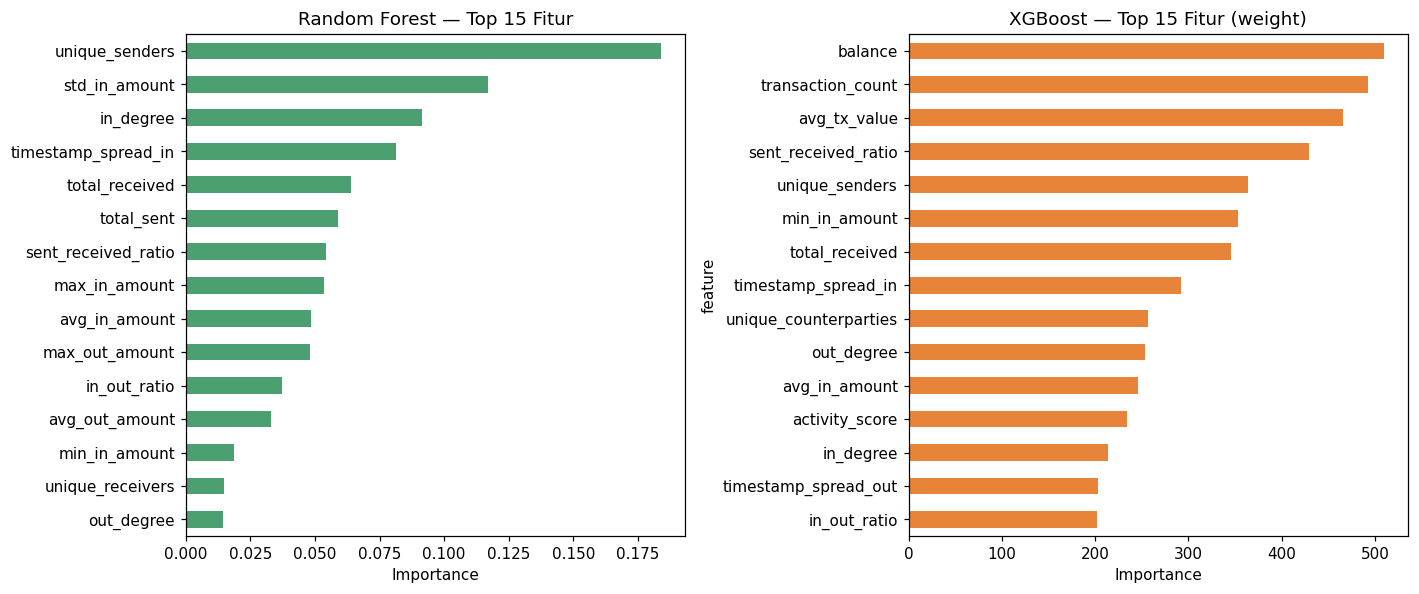

In [14]:
BEST = "muldigraph_plus_etherscan"
feats = scenario_feats[BEST]
rf = models_fitted[(BEST,"RandomForest")]
xm = models_fitted[(BEST,"XGBoost")]

rf_imp = pd.Series(rf.feature_importances_, index=feats).sort_values(ascending=False).head(15)
xgb_imp = xm.get_feature_importance(top_n=15).set_index("feature")["importance"]

fig, axes = plt.subplots(1, 2, figsize=(13,5.5))
rf_imp[::-1].plot(kind="barh", ax=axes[0], color="#4c9f70")
axes[0].set_title("Random Forest — Top 15 Fitur"); axes[0].set_xlabel("Importance")
xgb_imp[::-1].plot(kind="barh", ax=axes[1], color="#e8833a")
axes[1].set_title("XGBoost — Top 15 Fitur (weight)"); axes[1].set_xlabel("Importance")
plt.tight_layout(); plt.show()

## 7. 🧪 Eksperimen Sampling Ratio 1:5 vs 1:10 (RQ3)

Membangun dataset langsung dari MulDiGraph pada dua rasio undersampling, lalu
melatih LR & RF. Membuktikan pilihan rasio 1:10 di tesis.

In [15]:
if RUN_SAMPLING and G is not None:
    from ml.preprocess import extract_node_features
    phishing_nodes = [n for n,d in G.nodes(data=True) if d.get("isp",0)==1]
    normal_nodes   = [n for n,d in G.nodes(data=True) if d.get("isp",0)==0]
    print(f"phishing={len(phishing_nodes)}  normal={len(normal_nodes):,}")

    def run_ratio(ratio):
        n_sample = min(len(phishing_nodes)*ratio, len(normal_nodes))
        random.seed(SEED)
        sampled = random.sample(normal_nodes, n_sample)
        nodes = [(n,1) for n in phishing_nodes] + [(n,0) for n in sampled]
        recs = []
        for node, lab in nodes:
            f = extract_node_features(G, node); f["label"]=lab; recs.append(f)
        d = pd.DataFrame(recs); fc=[c for c in d.columns if c!="label"]
        X=d[fc].fillna(0).values; y=d["label"].values
        Xtr,Xte,ytr,yte = train_test_split(X,y,test_size=0.2,random_state=SEED,stratify=y)
        out=[]
        sc=StandardScaler(); lr=LogisticRegression(max_iter=1000,random_state=SEED,class_weight="balanced")
        lr.fit(sc.fit_transform(Xtr),ytr); lp=lr.predict(sc.transform(Xte))
        rf=RandomForestClassifier(n_estimators=200,min_samples_leaf=2,class_weight="balanced",n_jobs=-1,random_state=SEED)
        rf.fit(Xtr,ytr); rp=rf.predict(Xte)
        for nm,pr in [("LogisticRegression",lp),("RandomForest",rp)]:
            out.append(dict(ratio=f"1:{ratio}",model=nm,n_total=len(d),
                            accuracy=accuracy_score(yte,pr),precision=precision_score(yte,pr,zero_division=0),
                            recall=recall_score(yte,pr,zero_division=0),f1=f1_score(yte,pr,zero_division=0),
                            cm=confusion_matrix(yte,pr)))
        return out

    samp = []
    for r in [5,10]:
        print(f"  running 1:{r} ..."); samp += run_ratio(r)
    samp_df = pd.DataFrame(samp)
else:
    print("MulDiGraph tak ada → memuat hasil dari artifact sampling_experiment.json")
    samp_df = pd.DataFrame(json.load(open(ART/"sampling_experiment.json")))
    samp_df["cm"] = None

phishing=1165  normal=2,972,324
  running 1:5 ...


  running 1:10 ...


12:29:18  INFO      Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


12:29:18  INFO      Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


12:29:18  INFO      Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


12:29:18  INFO      Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


ratio              model  n_total  accuracy  precision  recall      f1
  1:5 LogisticRegression     6990   95.2800    90.3400 80.2600 85.0000
  1:5       RandomForest     6990   97.7100    91.3600 95.2800 93.2800
 1:10 LogisticRegression    12815   95.0400    75.0000 68.2400 71.4600
 1:10       RandomForest    12815   97.8200    88.3100 87.5500 87.9300


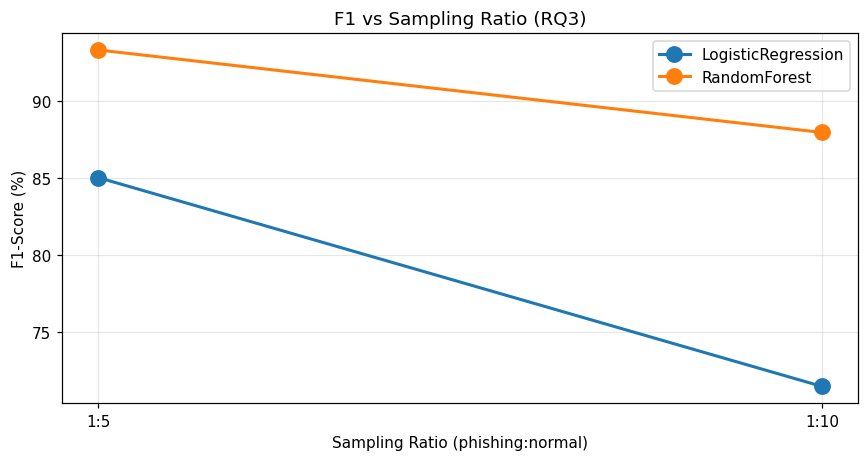

In [16]:
sv = samp_df.drop(columns=[c for c in ["cm"] if c in samp_df]).copy()
for c in ["accuracy","precision","recall","f1"]:
    sv[c] = (sv[c]*100).round(2)
print(sv.to_string(index=False))

fig, ax = plt.subplots(figsize=(8,4.3))
for model, grp in samp_df.groupby("model"):
    ax.plot(grp["ratio"], grp["f1"]*100, "o-", label=model, lw=2, ms=10)
ax.set_ylabel("F1-Score (%)"); ax.set_xlabel("Sampling Ratio (phishing:normal)")
ax.set_title("F1 vs Sampling Ratio (RQ3)"); ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

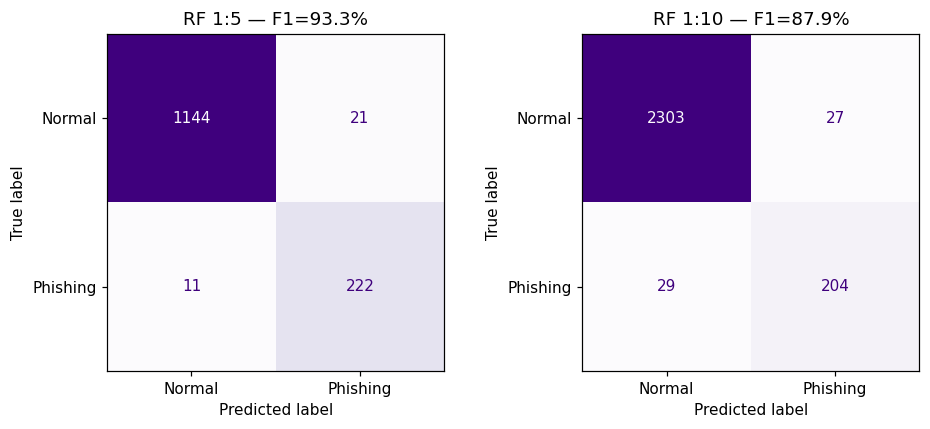

In [17]:
# Confusion matrix RF pada kedua rasio (jika tersedia)
if "cm" in samp_df and samp_df["cm"].notna().any():
    rf_rows = samp_df[samp_df.model=="RandomForest"]
    fig, axes = plt.subplots(1, len(rf_rows), figsize=(4.4*len(rf_rows),4))
    if len(rf_rows)==1: axes=[axes]
    for ax,(_,row) in zip(axes, rf_rows.iterrows()):
        ConfusionMatrixDisplay(row["cm"], display_labels=["Normal","Phishing"]).plot(
            ax=ax, colorbar=False, cmap="Purples", values_format="d")
        ax.set_title(f"RF {row['ratio']} — F1={row['f1']*100:.1f}%")
    plt.tight_layout(); plt.show()
else:
    print("Confusion matrix sampling hanya tersedia saat dijalankan live (RUN_SAMPLING=True).")

## 8. 🎚️ Threshold Analysis — XGBoost (Penguatan Akademik)

Default threshold 0.5 belum tentu optimal untuk F1. Sweep di sini menunjukkan
threshold mana yang memaksimalkan F1, melengkapi metrik standar.

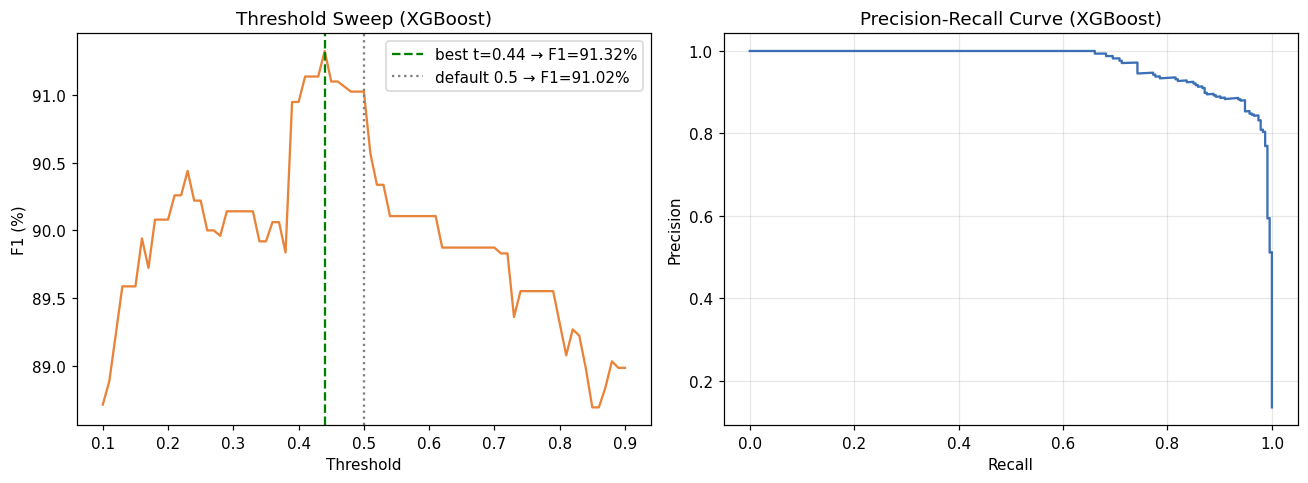

Default 0.5 F1 = 91.02%  |  Best t=0.44 F1 = 91.32%


In [18]:
feats = scenario_feats[BEST]
Xtr = train_df[feats].fillna(0).values; ytr = train_df["label"].values
Xte = test_df[feats].fillna(0).values
xm = models_fitted[(BEST,"XGBoost")]
proba = xm.predict_proba(Xte)[:,1]

ths = np.linspace(0.1, 0.9, 81)
f1s = [f1_score(y_test, (proba>=t).astype(int), zero_division=0) for t in ths]
best_t = ths[int(np.argmax(f1s))]; best_f1 = max(f1s)
default_f1 = f1_score(y_test, (proba>=0.5).astype(int))

prec, rec, _ = precision_recall_curve(y_test, proba)
fig, axes = plt.subplots(1,2, figsize=(12,4.5))
axes[0].plot(ths, np.array(f1s)*100, color="#e8833a")
axes[0].axvline(best_t, ls="--", color="green", label=f"best t={best_t:.2f} → F1={best_f1*100:.2f}%")
axes[0].axvline(0.5, ls=":", color="gray", label=f"default 0.5 → F1={default_f1*100:.2f}%")
axes[0].set_xlabel("Threshold"); axes[0].set_ylabel("F1 (%)"); axes[0].set_title("Threshold Sweep (XGBoost)"); axes[0].legend()
axes[1].plot(rec, prec, color="#3b6fb6"); axes[1].set_xlabel("Recall"); axes[1].set_ylabel("Precision")
axes[1].set_title("Precision-Recall Curve (XGBoost)"); axes[1].grid(alpha=0.3)
plt.tight_layout(); plt.show()
print(f"Default 0.5 F1 = {default_f1*100:.2f}%  |  Best t={best_t:.2f} F1 = {best_f1*100:.2f}%")

## 9. 📑 Classification Report per Model (Skenario Terbaik)

In [19]:
for m in MODEL_ORDER:
    if (BEST, m) not in preds: continue
    print(f"\n===== {m} — {SCENARIOS[BEST]} =====")
    print(classification_report(y_test, preds[(BEST,m)],
          target_names=["Normal","Phishing"], digits=4, zero_division=0))


===== LogisticRegression — MulDiGraph + Etherscan =====
              precision    recall  f1-score   support

      Normal     0.9733    0.9825    0.9779      1486
    Phishing     0.8813    0.8283    0.8540       233

    accuracy                         0.9616      1719
   macro avg     0.9273    0.9054    0.9159      1719
weighted avg     0.9609    0.9616    0.9611      1719


===== RandomForest — MulDiGraph + Etherscan =====
              precision    recall  f1-score   support

      Normal     0.9864    0.9778    0.9821      1486
    Phishing     0.8659    0.9142    0.8894       233

    accuracy                         0.9692      1719
   macro avg     0.9261    0.9460    0.9357      1719
weighted avg     0.9701    0.9692    0.9695      1719


===== XGBoost — MulDiGraph + Etherscan =====
              precision    recall  f1-score   support

      Normal     0.9898    0.9812    0.9855      1486
    Phishing     0.8862    0.9356    0.9102       233

    accuracy                

## 10. ⛓️ Metrik Blockchain — Latency & Gas (RQ2)

20 transaksi nyata `setRisk()` ke smart contract di Hardhat localhost.

Transaksi : 20
Latency ms: mean 13.57  median 11.97  min 11.15  max 38.44
Gas       : mean 35462  min 35452  max 35464


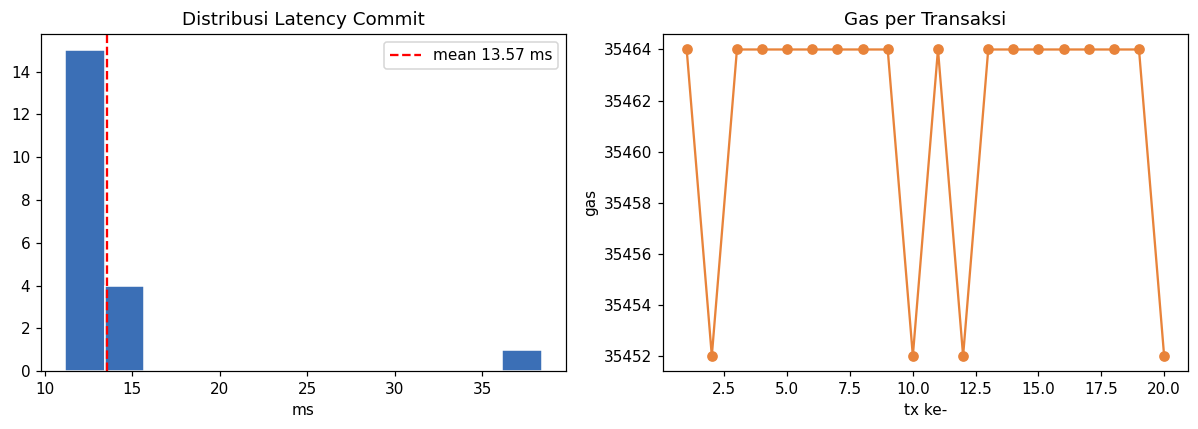

In [20]:
chain = json.load(open(ART/"blockchain_metrics.json"))
lat, gas = chain["latency_ms"], chain["gas_used"]
print(f"Transaksi : {chain['n_calls']}")
print(f"Latency ms: mean {lat['mean']}  median {lat['median']}  min {lat['min']}  max {lat['max']}")
print(f"Gas       : mean {gas['mean']}  min {gas['min']}  max {gas['max']}")
fig, axes = plt.subplots(1,2, figsize=(11,4))
axes[0].hist(chain["raw_latencies"], bins=12, color="#3b6fb6", edgecolor="white")
axes[0].axvline(lat["mean"], color="red", ls="--", label=f"mean {lat['mean']} ms"); axes[0].legend()
axes[0].set_title("Distribusi Latency Commit"); axes[0].set_xlabel("ms")
axes[1].plot(range(1,len(chain["raw_gas"])+1), chain["raw_gas"], "o-", color="#e8833a")
axes[1].set_title("Gas per Transaksi"); axes[1].set_xlabel("tx ke-"); axes[1].set_ylabel("gas")
plt.tight_layout(); plt.show()

## 11. ✅ Ringkasan & Jawaban Research Questions

In [21]:
print("="*60)
print("RINGKASAN EKSPERIMEN")
print("="*60)
best = res.loc[res.f1.idxmax()]
print(f"Model terbaik : {best['model']}")
print(f"Skenario      : {SCENARIOS[best['scenario']]}")
print(f"F1-Score      : {best['f1']*100:.2f}%  (acc {best['accuracy']*100:.2f}%, "
      f"prec {best['precision']*100:.2f}%, recall {best['recall']*100:.2f}%)")
if HAVE_TORCH:
    g = res[(res.scenario==best['scenario'])&(res.model=='GNN-GraphSAGE-V2')]
    if len(g): print(f"GNN-GraphSAGE : F1 {g['f1'].iloc[0]*100:.2f}% (recall {g['recall'].iloc[0]*100:.2f}%)")
print("\nRQ1: RF >> LR baseline pada semua skenario.")
print("RQ2: commit risk score ~14ms & gas ~35.462 (Hardhat) — overhead wajar.")
print("RQ3: fitur Etherscan menaikkan F1 semua model; rasio 1:10 dipilih utk estimasi konservatif.")

RINGKASAN EKSPERIMEN
Model terbaik : XGBoost
Skenario      : MulDiGraph + Etherscan
F1-Score      : 91.02%  (acc 97.50%, prec 88.62%, recall 93.56%)
GNN-GraphSAGE : F1 89.60% (recall 96.14%)

RQ1: RF >> LR baseline pada semua skenario.
RQ2: commit risk score ~14ms & gas ~35.462 (Hardhat) — overhead wajar.
RQ3: fitur Etherscan menaikkan F1 semua model; rasio 1:10 dipilih utk estimasi konservatif.


---
**Catatan reproducibility:** seluruh eksperimen memakai `random_state=42`. Untuk hasil
GNN yang identik dengan tesis, pastikan `MulDiGraph.pkl` ada di `data/raw/` dan
`USE_REAL_EDGES=True` (memakai edge transaksi nyata, bukan kNN sintetis).